# 2. WHO FluNet – virologický dohľad nad chrípkou (celý svet, týždenne)

**Zdroj:** https://www.who.int/tools/flunet  · dáta z národných chrípkových centier (GISRS)  
**Obdobie:** od 1995 · **Krajiny:** celý svet · Slovensko = `COUNTRY_CODE == "SVK"`

Plný CSV je veľký (desiatky MB) – sťahovanie môže trvať minútu. Ručne: stránka FluNet → *Download the full dataset* → **FluNet dataset (CSV)**.

In [2]:
# Ak chýbajú knižnice, odkomentujte:
# !pip install pandas requests matplotlib
import os, io, datetime
import requests
import pandas as pd
import matplotlib.pyplot as plt

OUT = "data_raw"
os.makedirs(OUT, exist_ok=True)
DNES = datetime.date.today().isoformat()
print("Dátum stiahnutia:", DNES)

Dátum stiahnutia: 2026-10-26


## Stiahnutie celého datasetu a dátového slovníka

In [3]:
URL_DATA = "https://xmart-api-public.who.int/FLUMART/VIW_FNT?$format=csv"
URL_SLOVNIK = ("https://xmart-api-public.who.int/FLUMART/VIW_FLU_METADATA?$format=csv"
               "&$filter=contains(DatasetName,%20'FluNet')")

def stiahni(url, subor):
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(subor, "wb") as f:
            for kus in r.iter_content(1 << 20):
                f.write(kus)
    print(f"{subor}: {os.path.getsize(subor)/1e6:.1f} MB")

stiahni(URL_DATA, f"{OUT}/who_flunet.csv")
stiahni(URL_SLOVNIK, f"{OUT}/who_flunet_slovnik.csv")

data_raw/who_flunet.csv: 32.3 MB
data_raw/who_flunet_slovnik.csv: 0.0 MB


In [4]:
flunet = pd.read_csv(f"{OUT}/who_flunet.csv", low_memory=False)
slovnik = pd.read_csv(f"{OUT}/who_flunet_slovnik.csv")
print(flunet.shape)
print(list(flunet.columns))

(189882, 53)
['WHOREGION', 'FLUSEASON', 'HEMISPHERE', 'ITZ', 'COUNTRY_CODE', 'COUNTRY_AREA_TERRITORY', 'ISO_WEEKSTARTDATE', 'ISO_YEAR', 'ISO_WEEK', 'MMWR_WEEKSTARTDATE', 'MMWR_YEAR', 'MMWR_WEEK', 'ORIGIN_SOURCE', 'SPEC_PROCESSED_NB', 'SPEC_RECEIVED_NB', 'AH1N12009', 'AH1', 'AH3', 'AH5', 'AH7N9', 'ANOTSUBTYPED', 'ANOTSUBTYPABLE', 'AOTHER_SUBTYPE', 'AOTHER_SUBTYPE_DETAILS', 'INF_A', 'BVIC_2DEL', 'BVIC_3DEL', 'BVIC_NODEL', 'BVIC_DELUNK', 'BYAM', 'BNOTDETERMINED', 'INF_B', 'INF_ALL', 'INF_NEGATIVE', 'ILI_ACTIVITY', 'ADENO', 'BOCA', 'HUMAN_CORONA', 'METAPNEUMO', 'PARAINFLUENZA', 'RHINO', 'RSV_PROCESSED', 'RSV', 'OTHERRESPVIRUS', 'OTHER_RESPVIRUS_DETAILS', 'LAB_RESULT_COMMENT', 'WCR_COMMENT', 'ISO2', 'ISOYW', 'MMWRYW', 'PSOURCE_SUBTYPE_INF', 'PSOURCE_PPOS_INF', 'PSOURCE_RSV']


In [5]:
# Vysvetlenie stĺpcov (dátový slovník)
pd.set_option("display.max_colwidth", 120)
slovnik

,DatasetName,TableName,FieldName,DataType,Description,Comments
0,FluNet,VIW_FNT,WHOREGION,string,"WHO regions (AFR, AMR, EMR, EUR, SEAR, WPR)",see: https://www.who.int/about/structure
1,FluNet,VIW_FNT,FLUSEASON,string,"Reporting season (NH=northern hemisphere, SH=southern hemisphere, YR=year-round reporting)",NaN
2,FluNet,VIW_FNT,HEMISPHERE,string,"Hemisphere (NH=northern hemisphere, SH=southern hemisphere)",NaN
3,FluNet,VIW_FNT,ITZ,string,Influenza transmission zone,see: https://cdn.who.int/media/docs/default-source/influenza/influenza-transmission-zones20180914.pdf
4,FluNet,VIW_FNT,COUNTRY_CODE,string,ISO3 country codes,includes WHO defined codes if not ISO3 code available
5,FluNet,VIW_FNT,COUNTRY_AREA_TERRITORY,string,"Country, area or territory name",NaN
6,FluNet,VIW_FNT,ISO2,string,ISO2 country code,includes WHO defined codes if not ISO3 code available
7,FluNet,VIW_FNT,ISO_WEEKSTARTDATE,date,Week start date (ISO 8601),NaN
8,FluNet,VIW_FNT,ISO_YEAR,integer,Year (ISO 8601),NaN
9,FluNet,VIW_FNT,ISO_WEEK,integer,Week (ISO 8601),NaN


## Slovensko a EÚ

In [6]:
sk = flunet[flunet.COUNTRY_CODE == "SVK"].copy()
sk["datum"] = pd.to_datetime(sk.ISO_WEEKSTARTDATE)
sk = sk.sort_values("datum")
print(len(sk), "SK riadkov,", sk.datum.min().date(), "→", sk.datum.max().date())
sk.head()

1768 SK riadkov, 1996-12-30 → 2026-10-12


,WHOREGION,FLUSEASON,HEMISPHERE,ITZ,COUNTRY_CODE,COUNTRY_AREA_TERRITORY,ISO_WEEKSTARTDATE,ISO_YEAR,ISO_WEEK,MMWR_WEEKSTARTDATE,...,OTHER_RESPVIRUS_DETAILS,LAB_RESULT_COMMENT,WCR_COMMENT,ISO2,ISOYW,MMWRYW,PSOURCE_SUBTYPE_INF,PSOURCE_PPOS_INF,PSOURCE_RSV,datum
155997,EUR,NH,NH,FLU_EST_EUR,SVK,Slovakia,1996-12-30,1997,1,1996-12-29,...,NaN,NaN,Unclear: week ending Jan. 15th?\nInfluenza-like illness is slowly increasing.\nLocal outbreaks from schools. Influe...,SK,199701,199701,NaN,NaN,NaN,1996-12-30
155998,EUR,NH,NH,FLU_EST_EUR,SVK,Slovakia,1997-01-13,1997,3,1997-01-12,...,NaN,NaN,"Jan. 28th, 1997\nMorbidity rates increased but on the level normal for the season.\nViruses isolated among soldiers ...",SK,199703,199703,NaN,NaN,NaN,1997-01-13
155999,EUR,NH,NH,FLU_EST_EUR,SVK,Slovakia,1997-02-03,1997,6,1997-02-02,...,NaN,NaN,NaN,SK,199706,199706,NaN,NaN,NaN,1997-02-03
156000,EUR,NH,NH,FLU_EST_EUR,SVK,Slovakia,1997-02-10,1997,7,1997-02-09,...,NaN,NaN,NaN,SK,199707,199707,NaN,NaN,NaN,1997-02-10
156001,EUR,NH,NH,FLU_EST_EUR,SVK,Slovakia,1997-02-24,1997,9,1997-02-23,...,NaN,NaN,NaN,SK,199709,199709,NaN,NaN,NaN,1997-02-24


ORIGIN_SOURCE
NONSENTINEL    680
NOTDEFINED     408
SENTINEL       680
dtype: int64


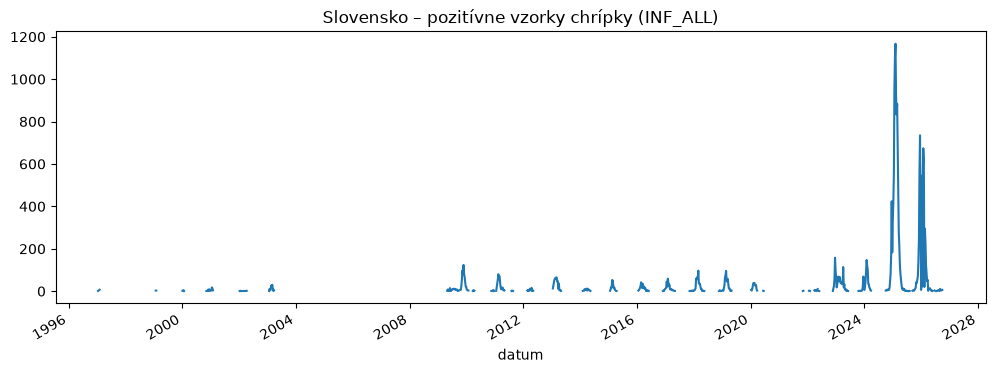

In [7]:
# Pozn.: jedna krajina môže mať viac riadkov za týždeň (rôzne typy zdrojov – ORIGIN_SOURCE).
print(sk.groupby("ORIGIN_SOURCE").size() if "ORIGIN_SOURCE" in sk else "bez ORIGIN_SOURCE")

# Pozitívne chrípkové vzorky a počet testovaných, súčet za týždeň
tyzden = sk.groupby("datum")[["INF_ALL", "SPEC_PROCESSED_NB"]].sum(min_count=1)
tyzden["pozitivita_%"] = 100 * tyzden.INF_ALL / tyzden.SPEC_PROCESSED_NB
tyzden["INF_ALL"].plot(figsize=(12, 4), title="Slovensko – pozitívne vzorky chrípky (INF_ALL)")
plt.show()

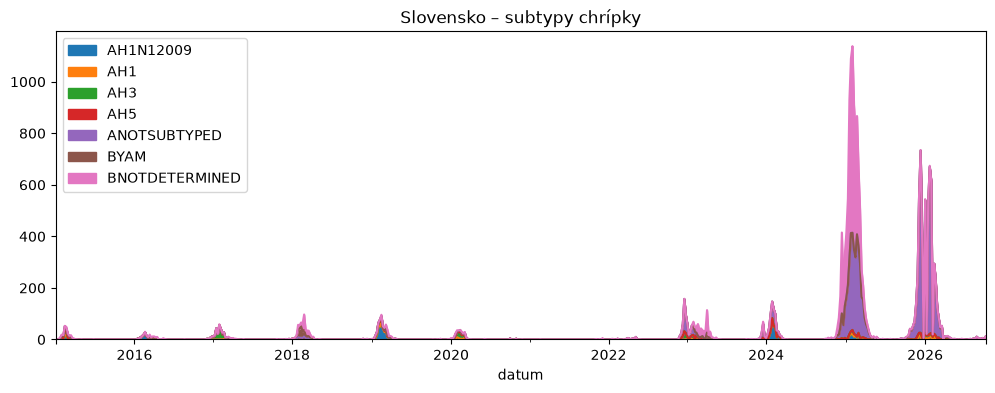

In [8]:
# Subtypy chrípky (stĺpce, ktoré v datasete existujú)
subtypy = [c for c in ["AH1N12009", "AH1", "AH3", "AH5", "ANOTSUBTYPED", "BVIC", "BYAM", "BNOTDETERMINED"] if c in sk.columns]
sk.groupby("datum")[subtypy].sum(min_count=1).loc["2015":].plot.area(figsize=(12, 4), title="Slovensko – subtypy chrípky")
plt.show()

In [9]:
# Krajiny EÚ27 pre porovnanie SK s EÚ
EU27 = ["AUT","BEL","BGR","HRV","CYP","CZE","DNK","EST","FIN","FRA","DEU","GRC","HUN","IRL","ITA",
        "LVA","LTU","LUX","MLT","NLD","POL","PRT","ROU","SVK","SVN","ESP","SWE"]
eu = flunet[flunet.COUNTRY_CODE.isin(EU27)].copy()
eu["datum"] = pd.to_datetime(eu.ISO_WEEKSTARTDATE)
print(len(eu), "riadkov EÚ27")
eu.to_csv(f"{OUT}/who_flunet_EU27.csv", index=False)
sk.to_csv(f"{OUT}/who_flunet_SK.csv", index=False)
print("Uložené SK a EÚ27 výbery | stiahnuté:", DNES)

43669 riadkov EÚ27
Uložené SK a EÚ27 výbery | stiahnuté: 2026-10-26
